# BatChat vs the crowd: where Batman fans disagree

BatChat ranks *Red Rain* sixth, despite its **3.66/5 on Goodreads**. *White Knight* gets **4.28**, yet lands at **#734** on the podcast's list. That's a substantial disagreement about what makes a good Batman comic. [Red Rain rating](https://www.goodreads.com/book/show/72479.Batman_Dracula) · [White Knight rating](https://www.goodreads.com/book/show/37775321-batman)

We'll compare the [BatChat podcast's rankings](https://comicsxf.com/batchat-rankings/) with Goodreads readers, Comic Book RoundUp readers, and RoundUp critics. The dataset contains **740 stories**, captured on **21 October 2026**; **rank 1 is best**. Some disagreements recur across all three sources. The apparent difference between reader and critic agreement, though, largely disappears when we compare the same books.

Everything runs from the attached snapshot. These are retrospective comparisons: outside ratings may postdate the episode, and each platform attracts its own audience.

<details><summary>Rank and metric conventions</summary>

Rank follows page order because the source repeats some printed numbers. Lower ranks and lower prediction errors are better; higher ratings are better. Signed differences are defined beside each chart. The [metric key](../references/data_dictionary.md#analysis-metrics-and-sign-conventions) documents the exported columns.

</details>

*Part of [BatRank](https://github.com/ddofer/BatRank), by [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ).*

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), Path.cwd().parent]
candidates += [p.parents[2] for p in Path('/kaggle/input').glob('**/data/processed/stories.csv')]
DATA_ROOT = next(p for p in candidates if (p/'data/processed/stories.csv').exists())
sys.path.insert(0, str(DATA_ROOT))
from scripts.analysis import (load_data, split_set, grouped_folds, feature_frame, regression,
    fit_oof, model_summary, bootstrap_gain, block_importance, creator_table, save_figure,
    COLORS, ROLES, BIBLIOGRAPHY, CRAFT, CAST, AWARDS, AWARD_CONTROLS)
ROOT, REPORT, s, issues = load_data()
N = len(s)
s['preference'] = 1-s.rank_percentile
print(f'{N:,} ranked entries · {len(issues):,} issue references · snapshot {s.snapshot_date.iloc[0]}')


740 ranked entries · 2,434 issue references · snapshot 2026-10-21


## 1. Are we rating the same comic?

*Court of Owls* Volume 1 ends before BatChat's selection does, while *Ego and Other Tails* includes more than *Ego*. We exclude these mismatches. Goodreads must cover the same narrative; RoundUp must cover every issue, with no unrelated stories sharing the issue-level score. Otherwise, a review of an *Elegy* issue might partly be a review of its backup.

We average an arc's issue scores equally. After matching contents and applying minimum-vote thresholds, **55 Goodreads matches become 40**, **326 RoundUp reader matches become 110**, and **174 critic matches become 78**.

In [2]:
sources={
    'Goodreads readers':{'score':'goodreads_rating','count':'goodreads_rating_count','minimum':100},
    'RoundUp readers':{'score':'roundup_user_rating','count':'roundup_user_min_count','minimum':5},
    'RoundUp critics':{'score':'roundup_critic_rating','count':'roundup_critic_min_count','minimum':3},
}
def eligibility(label,minimum=None):
    spec=sources[label]
    minimum=spec['minimum'] if minimum is None else minimum
    if label=='Goodreads readers':
        match=s.goodreads_match_scope.eq('same_story')
    else:
        audience='user' if label=='RoundUp readers' else 'critic'
        match=s[f'roundup_{audience}_complete'] & s.roundup_narrative_scope.eq('all_indexed_narratives')
    return match & s[spec['count']].ge(minimum)

coverage=[]
for label,spec in sources.items():
    ok=eligibility(label)
    coverage.append({'audience':label,'any_score':s[spec['score']].notna().sum(),
                     'matched_and_count_screened':ok.sum(),'median_BatChat_rank':s.loc[ok,'rank'].median()})
coverage=pd.DataFrame(coverage)
display(coverage.rename(columns={'audience':'Audience','any_score':'Any score found',
    'matched_and_count_screened':'Comparable stories','median_BatChat_rank':'Median BatChat rank · lower = better'}).set_index('Audience'))
coverage.to_csv(REPORT/'external_rating_coverage.csv',index=False)


,Any score found,Comparable stories,Median BatChat rank · lower = better
Audience,,,
Goodreads readers,55,40,113.5
RoundUp readers,326,110,245.0
RoundUp critics,174,78,282.5


Goodreads covers a particularly favored slice of BatChat's list: its matched books have a **median rank of 113.5**, versus **245.0** for RoundUp readers and **282.5** for critics. Keep that difference in mind when comparing the three panels below.

<details><summary>Which ratings qualify?</summary>

We require 100 Goodreads ratings, or at least five RoundUp reader ratings or three critic reviews for every issue. These are review counts, not independent people across an arc. Matching a narrative also leaves possible edition differences, including coloring and extras.

</details>

## 2. Do the audiences put the same books near the top?

There is modest agreement, with plenty of scatter. **Spearman correlation is 0.30 for RoundUp readers, 0.29 for Goodreads, and 0.20 for critics**; 1 would mean identical ordering. Each dot is a story, with higher outside scores to the right and better BatChat ranks toward the top.

The Goodreads and critic uncertainty intervals include zero. More importantly, these panels contain different books, so the correlations alone cannot establish whether the hosts agree more with readers or critics. We'll compare those audiences on a shared sample shortly.

<details><summary>Correlation and uncertainty</summary>

Spearman compares ordering without equating Goodreads stars with RoundUp points. We reverse BatChat's ranks so that positive correlation means agreement. Zero means no consistent monotonic relationship.

Estimates and 95% intervals are 0.302 [0.106, 0.496] for RoundUp readers, 0.288 [−0.058, 0.561] for Goodreads, and 0.199 [−0.062, 0.432] for critics. The bootstrap keeps connected episode and shared-issue groups together; it does not include uncertainty in the matches.

</details>

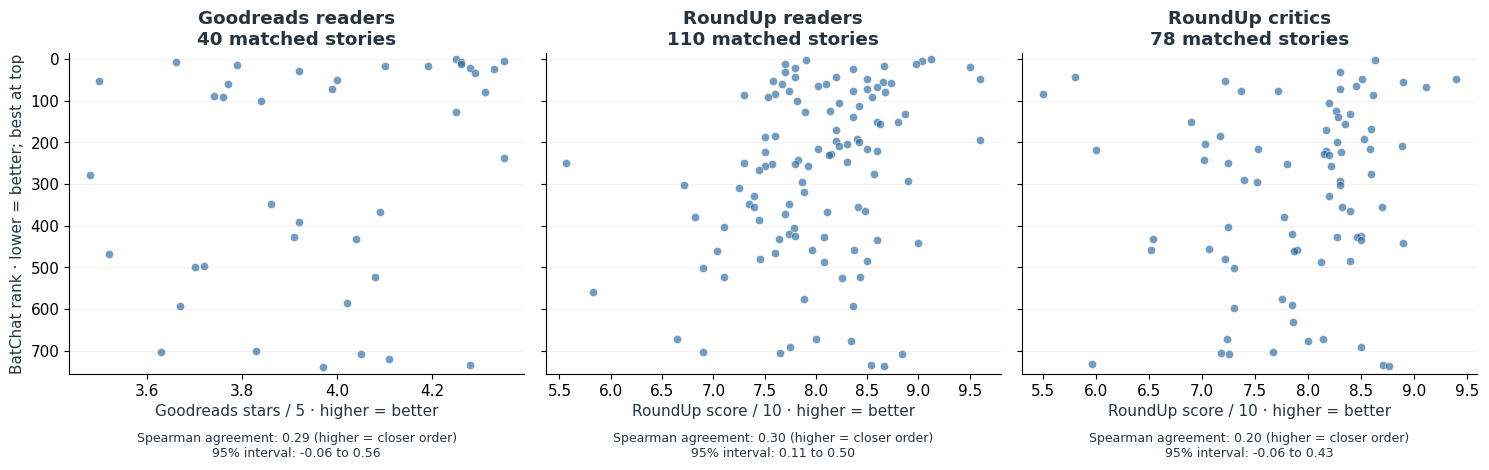

In [3]:
from scipy.stats import spearmanr
from scripts.analysis import correlation_interval
groups,folds=grouped_folds(s,issues)
cohorts={label:s[eligibility(label)].copy() for label in sources}

correlations=[]
fig,axes=plt.subplots(1,3,figsize=(15,5),sharey=True)
for ax,(label,frame) in zip(axes,cohorts.items()):
    column=sources[label]['score'];rho=spearmanr(frame.preference,frame[column]).statistic
    block=pd.Series(groups,index=s.index).loc[frame.index]
    low,high=correlation_interval(frame.preference,frame[column],block)
    correlations.append({'audience':label,'n':len(frame),'spearman':rho,'ci_low':low,'ci_high':high})
    ax.scatter(frame[column],frame['rank'],s=35,alpha=.65,color=COLORS['blue'],edgecolors='white',linewidth=.5)
    ax.set(title=f'{label}\n{len(frame)} matched stories',xlabel='Goodreads stars / 5 · higher = better' if label=='Goodreads readers' else 'RoundUp score / 10 · higher = better')
    ax.set_ylim(N+15,-15);ax.yaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
    ax.text(.5,-.26,f'Spearman agreement: {rho:.2f} (higher = closer order)\n95% interval: {low:.2f} to {high:.2f}',
            transform=ax.transAxes,fontsize=9,ha='center')
axes[0].set_ylabel('BatChat rank · lower = better; best at top')
fig.tight_layout();save_figure(fig,REPORT,'crowd-agreement')
correlations=pd.DataFrame(correlations)
correlations.to_csv(REPORT/'external_rating_correlations.csv',index=False)

## 3. The disagreements worth arguing about

Here's where those correlations become interesting. The chart orders **the same 40 Goodreads-matched books** for each audience, on a scale from 0 at the bottom to 100 at the top. Blue is BatChat; orange is Goodreads. Longer lines mean bigger disagreements.

*Red Rain* sits **84.6 points higher with BatChat**, while *White Knight* sits **83.3 points lower**. These are relative positions among the 40 books, rather than star differences or places on the full 740-story list.

<details><summary>Calculating the gaps</summary>

We rank scores within each matched sample, average tied ranks, and rescale to 0–100. The gap is BatChat's position minus the outside audience's position. Exported values use 0–1.

This measures disagreement between audiences. Individual rating distributions would be needed to measure how divisive a book is within one audience.

</details>

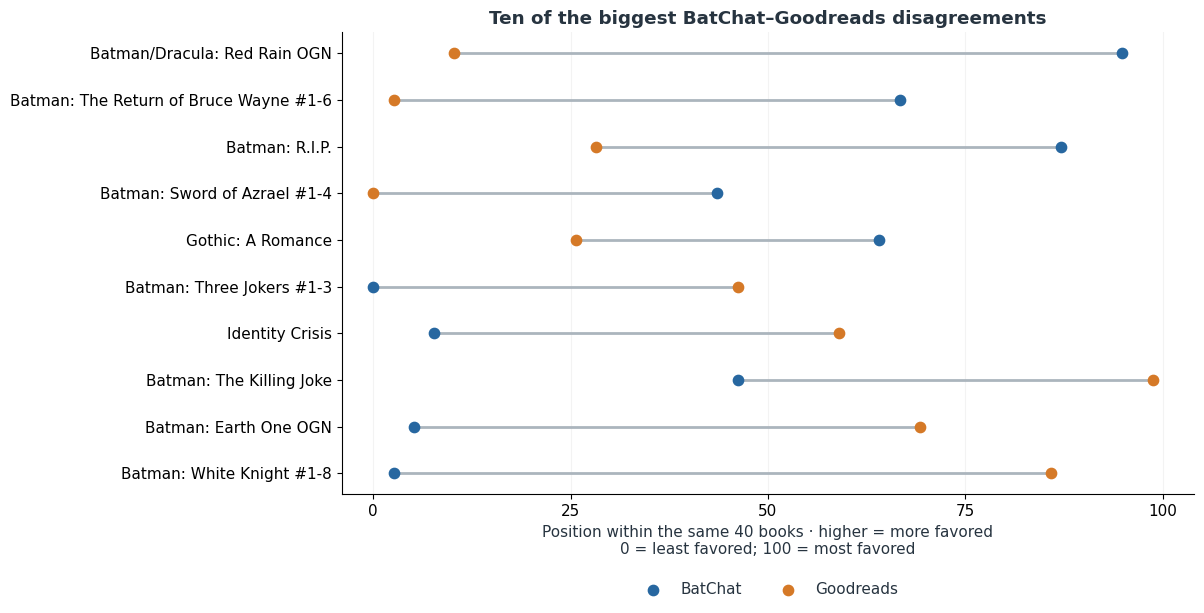

In [4]:
hot=[]
for label,frame in cohorts.items():
    frame=frame.copy();column=sources[label]['score']
    frame['batchat_cohort_percentile']=(frame.preference.rank(method='average')-1)/(len(frame)-1)
    frame['external_cohort_percentile']=(frame[column].rank(method='average')-1)/(len(frame)-1)
    frame['preference_gap']=frame.batchat_cohort_percentile-frame.external_cohort_percentile
    frame['audience']=label;frame['external_score']=frame[column]
    hot.append(frame)
hot=pd.concat(hot,ignore_index=True)
cols=['audience','story_id','title','rank','external_score','preference_gap','goodreads_url']
hot[cols].to_csv(REPORT/'external_hot_takes.csv',index=False)
shown=hot[hot.audience.eq('Goodreads readers')]
shown=pd.concat([shown.nlargest(5,'preference_gap'),shown.nsmallest(5,'preference_gap')]).sort_values('preference_gap')
fig,ax=plt.subplots(figsize=(11,6))
ax.hlines(shown.title,100*shown.batchat_cohort_percentile,100*shown.external_cohort_percentile,color='#ABB5BD',lw=2)
ax.scatter(100*shown.batchat_cohort_percentile,shown.title,color=COLORS['blue'],label='BatChat',s=55,zorder=3)
ax.scatter(100*shown.external_cohort_percentile,shown.title,color=COLORS['orange'],label='Goodreads',s=55,zorder=3)
ax.set(xlabel='Position within the same 40 books · higher = more favored\n0 = least favored; 100 = most favored',
       title='Ten of the biggest BatChat–Goodreads disagreements',xlim=(-4,104),xticks=[0,25,50,75,100])
ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.16),ncol=2,frameon=False);save_figure(fig,REPORT,'crowd-hot-takes')

*The Return of Bruce Wayne* is a consistent outlier: BatChat ranks it **#53**, placing it relatively higher than all three comparison audiences do. *White Knight* goes the other way across all three, and *Curse of the White Knight* also has a large RoundUp gap.

Both *Red Rain* and *White Knight* substantially rework Batman. Moench and Kelley Jones put him in a vampire tragedy; Murphy has a supposedly rehabilitated Joker challenge his power. Their opposite reception on BatChat makes “unconventional Batman” a pretty unhelpful explanation of the hosts' taste. [DC on Red Rain's trilogy](https://www.dc.com/graphic-novels/batman-and-dracula-trilogy-1991/tales-of-the-multiverse-batman-vampire) · [DC on White Knight](https://www.dc.com/blog/2017/07/07/sean-murphy-s-batman-white-knight-arrives-october-4)

*The Killing Joke* raises an edition problem worth studying. John Higgins's original colors and Brian Bolland's recoloring give the same story different visual treatments, but a pooled rating can merge those experiences. Edition-level scores would help, provided we also account for the readers choosing each version. [DC's edition comparison](https://www.dc.com/graphic-novels/absolute-batman-the-killing-joke)

## 4. More votes, different books

Demanding more ratings raises agreement at the strictest cutoffs. For RoundUp readers, moving from **five to twenty ratings per issue** raises correlation from **0.30 to 0.41**, but cuts the sample from **110 stories to 37**. For critics, moving from three to ten reviews raises it from **0.20 to 0.35**, leaving **39 stories instead of 78**.

The intermediate cutoffs do not improve agreement steadily. More votes may stabilize a score, but these thresholds also change which books we're comparing.

**69 stories pass both original RoundUp screens.** Their largest reader–critic differences are below, in points out of ten.

In [5]:
sensitivity=[]
thresholds={'Goodreads readers':[100,1000,5000,10000],
            'RoundUp readers':[1,3,5,10,20],'RoundUp critics':[1,3,5,10]}
for label,limits in thresholds.items():
    for minimum in limits:
        frame=s[eligibility(label,minimum)]
        if len(frame)>=8:
            sensitivity.append({'audience':label,'minimum_count':minimum,'n':len(frame),
                'spearman':spearmanr(frame.preference,frame[sources[label]['score']]).statistic})
sensitivity=pd.DataFrame(sensitivity)
sensitivity.to_csv(REPORT/'external_vote_sensitivity.csv',index=False)

paired=s[eligibility('RoundUp readers')&eligibility('RoundUp critics')].copy()
paired['critic_minus_reader']=paired.roundup_critic_rating-paired.roundup_user_rating

display(pd.concat([paired.nlargest(5,'critic_minus_reader'),paired.nsmallest(5,'critic_minus_reader')])[
    ['title','rank','roundup_critic_rating','roundup_user_rating','critic_minus_reader']].rename(columns={
    'title':'Story','rank':'BatChat rank · 1 = best','roundup_critic_rating':'Critics / 10 · higher = better',
    'roundup_user_rating':'Readers / 10 · higher = better','critic_minus_reader':'Critics − readers · positive = critics higher'}).set_index('Story').round(2))
paired[['story_id','title','rank','roundup_critic_rating','roundup_user_rating','critic_minus_reader']].to_csv(
    REPORT/'critic_reader_disagreements.csv',index=False)

,BatChat rank · 1 = best,Critics / 10 · higher = better,Readers / 10 · higher = better,Critics − readers · positive = critics higher
Story,,,,
Being Robin,250,7.25,5.57,1.68
Shadows,302,8.30,6.72,1.58
Batman: Black and White V.4,87,8.62,7.30,1.32
Sharkbite,356,8.70,7.40,1.30
Mindfields,380,7.78,6.82,0.95
Slay Ride,42,5.80,8.20,-2.40
The Clown at Midnight,85,5.50,7.60,-2.10
Batman and Son,458,6.52,8.38,-1.85
Blackest Knight,152,6.90,8.60,-1.70


*Slay Ride* has the largest reader-over-critic gap in this set: **8.2 versus 5.8**, with BatChat placing it at **#42**. *The Clown at Midnight* follows at **7.6 versus 5.5**; the hosts put that illustrated prose experiment at **#85**. Critics favor *Being Robin*, however, scoring it **7.25** against readers' **5.57**.

Those examples were selected for their large gaps. The full set of 69 gives a less dramatic answer to whether BatChat agrees more with readers or critics.

## 5. Give everyone the same books

**On the same 69 stories, BatChat's correlation is 0.18 with readers and 0.16 with critics.** That difference is too small to resolve. The earlier 0.30-versus-0.20 comparison partly reflected the different books available to each audience. Readers and critics correlate more strongly with each other, at **0.44**.

Ordering agreement is separate from scoring generosity. Two audiences could order every book identically while one gives everything an extra point. The right panel shows critic-minus-reader scores by publication decade: positive means critics gave higher scores, and the short bars mark medians.

<details><summary>Uncertainty in the audience comparison</summary>

The difference between reader and critic correlations with BatChat is 0.025, with a paired group-bootstrap interval of −0.224 to 0.303. Each resample uses the same books for both comparisons and keeps connected episode and shared-issue groups together.

</details>

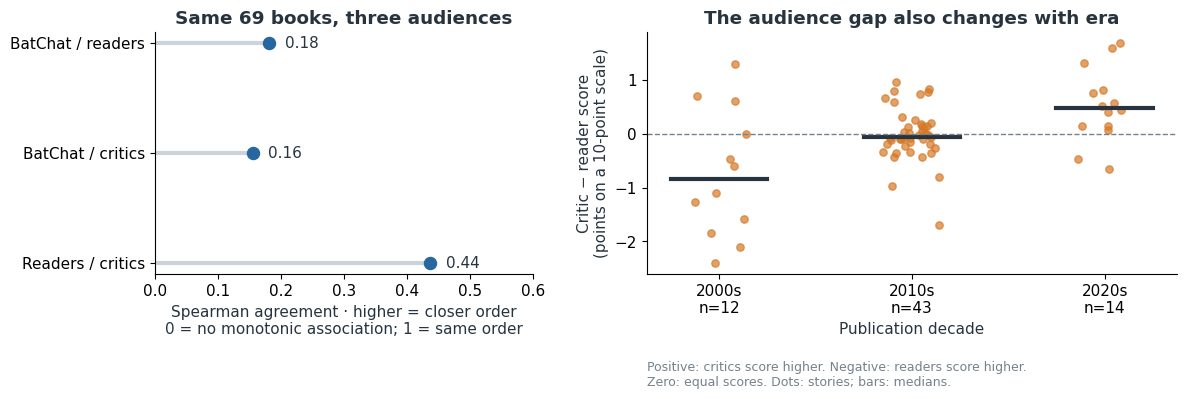

In [6]:
# Hold the books fixed for all three comparisons.
paired=s[eligibility('RoundUp readers') & eligibility('RoundUp critics')].copy()
paired['critic_minus_reader']=paired.roundup_critic_rating-paired.roundup_user_rating
paired['decade']=(paired.cover_year_start//10*10).astype(int)
pair_correlations=pd.DataFrame([
    {'comparison':'BatChat / readers','rho':spearmanr(-paired['rank'],paired.roundup_user_rating).statistic},
    {'comparison':'BatChat / critics','rho':spearmanr(-paired['rank'],paired.roundup_critic_rating).statistic},
    {'comparison':'Readers / critics','rho':spearmanr(paired.roundup_user_rating,paired.roundup_critic_rating).statistic},
])
values=paired[['rank','roundup_user_rating','roundup_critic_rating','cover_year_start','critic_minus_reader']].to_numpy()
labels=pd.Series(groups,index=s.index).loc[paired.index].to_numpy()
blocks=[np.flatnonzero(labels==g) for g in np.unique(labels)]
rng=np.random.default_rng(42)
bootstrap=[]
for _ in range(2000):
    draw=values[np.concatenate([blocks[k] for k in rng.integers(0,len(blocks),len(blocks))])]
    reader_rho=spearmanr(-draw[:,0],draw[:,1]).statistic
    critic_rho=spearmanr(-draw[:,0],draw[:,2]).statistic
    bootstrap.append([reader_rho-critic_rho,spearmanr(draw[:,3],draw[:,4]).statistic])
intervals=np.nanquantile(bootstrap,[.025,.975],axis=0)
comparison={
    'n_readings':len(paired),'n_connected_groups':len(blocks),
    'reader_minus_critic_rho':pair_correlations.rho.iloc[0]-pair_correlations.rho.iloc[1],
    'difference_ci_low':intervals[0,0],'difference_ci_high':intervals[1,0],
    'year_gap_rho':spearmanr(paired.cover_year_start,paired.critic_minus_reader).statistic,
    'year_gap_ci_low':intervals[0,1],'year_gap_ci_high':intervals[1,1],
}

(REPORT/'same_cohort_audiences.json').write_text(json.dumps(comparison,indent=2))
era_gaps=paired.groupby('decade').critic_minus_reader.agg(n='size',median='median')
era_gaps.to_csv(REPORT/'critic_reader_gap_by_era.csv')


fig,axes=plt.subplots(1,2,figsize=(12,4.5),gridspec_kw={'width_ratios':[1,1.4]})
axes[0].hlines(range(3),0,pair_correlations.rho,color='#CBD4DB',lw=3)
axes[0].scatter(pair_correlations.rho,range(3),s=75,color=COLORS['blue'],zorder=3)
for row in pair_correlations.itertuples():
    axes[0].text(row.rho+.025,row.Index,f'{row.rho:.2f}',va='center')
axes[0].set(yticks=range(3),yticklabels=pair_correlations.comparison,xlim=(0,.6),
            xlabel='Spearman agreement · higher = closer order\n0 = no monotonic association; 1 = same order',title=f'Same {len(paired)} books, three audiences')
axes[0].invert_yaxis()
jitter=np.random.default_rng(42)
for pos,(decade,row) in enumerate(era_gaps.iterrows()):
    gap=paired.loc[paired.decade.eq(decade),'critic_minus_reader']
    axes[1].scatter(pos+jitter.uniform(-.15,.15,len(gap)),gap,s=28,alpha=.7,color=COLORS['orange'])
    axes[1].plot([pos-.25,pos+.25],[row['median']]*2,color='#273440',lw=3)
axes[1].axhline(0,color=COLORS['grey'],lw=1,ls='--')
axes[1].set(xticks=range(len(era_gaps)),
            xticklabels=[f'{d}s\nn={int(r.n)}' for d,r in era_gaps.iterrows()],
            ylabel='Critic − reader score\n(points on a 10-point scale)',xlabel='Publication decade',
            title='The audience gap also changes with era')
axes[1].text(0,-.36,'Positive: critics score higher. Negative: readers score higher.\nZero: equal scores. Dots: stories; bars: medians.',
             transform=axes[1].transAxes,fontsize=9,color=COLORS['grey'],va='top')
fig.tight_layout();save_figure(fig,REPORT,'crowd-same-books')

# Check whether one reading or a low vote cutoff drives the era pattern.
leave_one_out=[spearmanr(paired.drop(j).cover_year_start,
                        paired.drop(j).critic_minus_reader).statistic for j in paired.index]

for reader_min,critic_min in [(10,5),(20,10)]:
    stricter=paired[paired.roundup_user_min_count.ge(reader_min) & paired.roundup_critic_min_count.ge(critic_min)]
    assert len(stricter)>2
assert len(paired)>2 and np.isfinite(pair_correlations.rho).all()


The median critic-minus-reader gap shifts from **−0.85 points for the 12 stories from the 2000s** to almost zero for **43 from the 2010s**, then **+0.48 for 14 from the 2020s**. The reader preference for *The Clown at Midnight* sits within a broader pattern among the older books in this sample.

The direction survives removing any single story and raising vote minimums. It doesn't establish that critics became more generous: the books and reviewers differ, and readers may rate older comics years after their original reviews.

<details><summary>Checks on the era pattern</summary>

Publication year correlates 0.552 with the critic-minus-reader gap. Dropping each story in turn leaves it between 0.532 and 0.604. Stricter vote thresholds retain a positive association while changing the sample.

These are aggregate scores. A middling average can reflect either broad indifference or a split between love and hate.

</details>

## 6. Do outside scores help predict BatChat?

A model using publication years, contributor names, characters, creative-team changes, and previous awards misses BatChat's ranks by **169.5 places on average**. We then tell it which books have usable outside ratings, how many votes they received, and finally the scores themselves.

Most of the improvement arrives before the model sees a rating. Knowing which books have usable ratings reduces the error to **166.6 places**; adding votes and scores eventually brings it to **166.4**.

<details><summary>Validation and features</summary>

All 740 stories receive held-out predictions from five folds that keep connected episode and shared-issue groups together. These are the groups used in [Notebook 1](1.0-batchat-rankings.ipynb). Preprocessing fits on training data only, and each model uses the same fixed Ridge penalty.

Availability flags remain in place as votes and scores enter. Missingness means no eligible match in this dataset, not necessarily no ratings. Vote intensity uses Goodreads' book-level count or RoundUp's mean review count per issue.

These are retrospective predictions because ratings may postdate the episode.

</details>

In [7]:
X=feature_frame(s);y=s['rank'].to_numpy(dtype=float)
flags=[];counts=[];scores=[]
for label,spec in sources.items():
    valid=eligibility(label)
    column=spec['score'];flag=column+'_available';count=column+'_log_count'
    X[column]=s[column].where(valid)
    X[flag]=valid.astype(float)
    observations=(s.goodreads_rating_count if label=='Goodreads readers' else
        s['roundup_user_count' if label=='RoundUp readers' else 'roundup_critic_count']/s.issue_reference_count)
    X[count]=np.log1p(observations).where(valid)
    flags.append(flag);counts.append(count);scores.append(column)
base=BIBLIOGRAPHY+CRAFT+AWARD_CONTROLS+AWARDS
tokens=['narrative_'+r for r in ROLES]+CAST
models={
    'Metadata':regression(base,tokens),
    '+ availability':regression(base+flags,tokens),
    '+ availability + votes':regression(base+flags+counts,tokens),
    '+ availability + votes + scores':regression(base+flags+counts+scores,tokens),
}
oof,fitted,fold_metrics=fit_oof(models,X,y,folds)
summary=model_summary(y,oof).drop(columns='Spearman').merge(
    fold_metrics.groupby('model').Spearman.mean().reset_index().rename(columns={'Spearman':'mean_fold_Spearman'}),on='model')
display(summary[['model','MAE_rank_places']].rename(columns={'model':'Information given to the model',
    'MAE_rank_places':'MAE in rank places · lower = better'}).set_index('Information given to the model').round(1));summary.to_csv(REPORT/'external_rating_cv.csv',index=False)
control='+ availability + votes';full='+ availability + votes + scores'
gain=bootstrap_gain(y,oof[control],oof[full],groups)

(REPORT/'external_score_gain.json').write_text(json.dumps(gain,indent=2))

rated=X[flags].any(axis=1).to_numpy()
from sklearn.metrics import mean_absolute_error
cohort_metrics=[]
for cohort,mask in [('All entries',np.ones(N,dtype=bool)),('At least one eligible external score',rated)]:
    for name,pred in oof.items():
        cohort_metrics.append({'cohort':cohort,'n':int(mask.sum()),'model':name,
                               'MAE_rank_places':mean_absolute_error(y[mask],pred[mask])})

pd.DataFrame(cohort_metrics).to_csv(REPORT/'external_rating_cv_cohorts.csv',index=False)
importance=block_importance(fitted[full],X,y,folds,{label:[spec['score']] for label,spec in sources.items()},repeats=10)
importance.to_csv(REPORT/'external_rating_importance.csv',index=False)

pred=s[['story_id','title','rank']].copy()
for name,values in oof.items():pred[name]=values
pred.to_csv(REPORT/'external_rating_predictions.csv',index=False)
assert np.isfinite(pred[list(models)]).all().all()

,MAE in rank places · lower = better
Information given to the model,
Metadata,169.5
+ availability,166.6
+ availability + votes,166.9
+ availability + votes + scores,166.4


Beyond availability and vote counts, **scores save an estimated 0.55 rank places**, with an interval of **−1.10 to 2.12**. Restricting evaluation to the **same 141 stories with an eligible score** changes error from **178.39 to 175.85 places**. Neither result suggests a substantial predictive gain.

The more useful findings concern specific books. *The Return of Bruce Wayne* ranks relatively higher with BatChat across all three comparisons; *White Knight* ranks lower. Meanwhile, the reader–critic difference nearly vanishes on a shared book list, and their score gap changes with publication era.

An edition comparison of *The Killing Joke* would be a good next study: record which coloring each reader saw, then test its association with their rating. That would connect reception to an actual difference on the page.

<details><summary>Download the numbers</summary>

`external_hot_takes.csv` contains audience-relative positions. `external_vote_sensitivity.csv` contains cutoff checks, and `critic_reader_disagreements.csv` compares the RoundUp audiences. Model results and held-out predictions are also in `reports/`.

The [data dictionary](../references/data_dictionary.md) documents the fields; the [Kaggle sharing guide](../references/kaggle-sharing.md) covers setup. All results use the saved snapshot. Model-gain intervals resample fixed held-out errors by connected group without refitting models.

</details>